# Stock Price Prediction and Machine Learning Model Deployment
**AnalystLab Africa · Machine Learning Engineering track · Week 6**

**Author:** Umar Muhammad  |  **Data:** S&P 500 daily stock prices 2014 – 2017 (497,472 records, 505 symbols, 1,007 trading dates)

> **Important.** This is a learning project about *method*. Historical performance does not guarantee future results, and nothing here is investment advice. All dates are 2014 – 2017 and must not be read as current market conditions.

---
## 0. Defining the prediction problem (Task 1)
| Item | Definition |
|---|---|
| **Stock selected** | **AAPL** (chosen in Section 3 on data-quality grounds) |
| **Prediction target** | The **closing price of the next trading day** (USD, assumed) |
| **Prediction horizon** | One trading day ahead |
| **Input features** | Previous day's close, open, high, low and volume; 5-, 10- and 20-day moving averages; previous day's % return (plus scale-free extras used by the return-target model) |
| **Business purpose** | A prototype that shows how a price-forecasting service is built, tested and deployed end to end, and an honest test of how much historical prices alone can tell us about tomorrow's price |
| **Intended user** | Analysts and data teams who need a forecasting prototype and a clear view of its limits |
| **Decisions it could support** | Short-term price expectations for monitoring and scenario work (**not** automated trading) |
| **Limitations of price-based prediction** | Daily returns are close to unpredictable from past prices; prices trend, so measures such as R² look excellent for any method; stock splits, spin-offs, dividends and news are not in the data |

**How this notebook is organised:** audit the data → choose the stock → explore → features and leakage tests → chronological split → baselines and MLflow experiments → evaluation, overfitting check and robustness → API → limitations.

## 1. Setup

In [1]:
%matplotlib inline
import json, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
import xgboost as xgb
from scipy import stats
from statsmodels.tsa.stattools import acf
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT))
from src.data_prep import load_raw, audit_dataset, get_stock, PRICE_COLS
from src.features import build_features, training_table, features_for_prediction, REQUIRED_FEATURES, RATIO_FEATURES, HISTORY_DAYS
from src.metrics import evaluate
from src.train import SPLITS, split, fit_xgb, to_price, DIRECT_CONFIGS

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 13, "axes.titleweight": "bold"})
PAL = sns.color_palette("deep")
IMG = ROOT / "images"; IMG.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMG / name, dpi=150, bbox_inches="tight"); plt.show()

## 2. Data inspection and quality audit
The original CSV is kept untouched in `data/raw/`. The assignment lists the data-quality issues found by an initial inspection and asks us to **verify them independently**.
### 2.1 Structure

In [2]:
raw_file = pd.read_csv(ROOT / "data/raw/S_P_500_Stock_Prices_2014-2017.csv", encoding="utf-8-sig", nrows=5)
print("First rows exactly as stored (dates are month/day/year text):"); display(raw_file)
df = load_raw()                         # parses dates with an explicit format and sorts by symbol, then date
print("Shape:", df.shape); print(df.dtypes.to_string())
print("\nIs the supplied file already ordered by symbol and date?",
      pd.read_csv(ROOT / "data/raw/S_P_500_Stock_Prices_2014-2017.csv", encoding="utf-8-sig").assign(date=lambda d: pd.to_datetime(d.date, format="%m/%d/%Y")).equals(df))

First rows exactly as stored (dates are month/day/year text):


,symbol,date,open,high,low,close,volume
0,AAL,1/2/2014,25.0700,25.8200,25.0600,25.3600,8998943
1,AAPL,1/2/2014,79.3828,79.5756,78.8601,79.0185,58791957
2,AAP,1/2/2014,110.3600,111.8800,109.2900,109.7400,542711
3,ABBV,1/2/2014,52.1200,52.3300,51.5200,51.9800,4569061
4,ABC,1/2/2014,70.1100,70.2300,69.4800,69.8900,1148391


Shape: (497472, 7)
symbol               str
date      datetime64[us]
open             float64
high             float64
low              float64
close            float64
volume             int64



Is the supplied file already ordered by symbol and date? False


The file is ordered by **date and then symbol**, not by symbol and date, so it is explicitly sorted by symbol and date before any return, lag or moving average is calculated (otherwise a calculation would mix two different companies).

### 2.2 Verifying the assignment's data-quality statements

In [3]:
audit = audit_dataset(df)
claims = pd.DataFrame([
    ["Total records", "497,472", f"{audit['rows']:,}"], ["Total columns", "7", audit["columns"]], ["Unique symbols", "505", audit["symbols"]],
    ["Distinct trading dates", "1,007", audit["dates"]], ["Missing open values", "11", audit["missing"]["open"]],
    ["Missing high values", "8", audit["missing"]["high"]], ["Missing low values", "8", audit["missing"]["low"]],
    ["Duplicate symbol-date combinations", "None", audit["duplicate_symbol_date"]], ["Zero-volume observations", "4", audit["zero_volume_rows"]],
    ["Incomplete stock histories", "Present", f"{audit['symbols_incomplete']} symbols (shortest: {audit['shortest_history']['symbol']}, {audit['shortest_history']['days']} days)"],
], columns=["Check", "Assignment says", "Verified"])
display(claims)
extra = pd.DataFrame([["Rows where high/low contradict open/close (e.g. close above high)", audit["ohlc_inconsistent_rows"]],
                      ["Daily moves above 25% (close to close)", audit["moves_over_25pct"]], ["Daily moves above 40%", audit["moves_over_40pct"]],
                      ["Non-positive prices", audit["nonpositive_prices"]], ["Zero-volume rows where open, high and low are all missing", f"{audit['zero_volume_rows']} of {audit['zero_volume_rows']}" if audit["zero_volume_all_prices_missing"] else "no"]],
                     columns=["Additional check (not in the assignment)", "Result"])
display(extra)

,Check,Assignment says,Verified
0,Total records,"497,472","497,472"
1,Total columns,7,7
2,Unique symbols,505,505
3,Distinct trading dates,"1,007",1007
4,Missing open values,11,11
5,Missing high values,8,8
6,Missing low values,8,8
7,Duplicate symbol-date combinations,None,0
8,Zero-volume observations,4,4
9,Incomplete stock histories,Present,"26 symbols (shortest: APTV, 18 days)"


,Additional check (not in the assignment),Result
0,Rows where high/low contradict open/close (e.g...,12
1,Daily moves above 25% (close to close),39
2,Daily moves above 40%,10
3,Non-positive prices,0
4,"Zero-volume rows where open, high and low are ...",4 of 4


**All of the assignment's statements are confirmed.** Two further findings matter for modelling:
* **The four zero-volume rows are placeholders, not real trading days:** open, high and low are all missing and volume is 0 (the close is a carried-over value). They must not be used as ordinary observations.
* **12 rows have inconsistent prices** (for example a close above the day's high), a sign of small data errors elsewhere in the file.

### 2.3 Missing values, zero volume and incomplete histories

11 rows with a missing open, high or low:


,symbol,date,open,high,low,close,volume
66487,BHF,2017-07-26,NaN,NaN,NaN,69.0842,3
133913,DHR,2015-07-17,NaN,88.76,88.24,88.7200,2056819
134036,DHR,2016-01-12,NaN,NaN,NaN,88.5500,0
162370,ES,2015-07-17,NaN,48.49,47.85,47.9200,1246786
193471,FTV,2016-07-01,NaN,NaN,NaN,49.5400,0
343994,O,2015-07-17,NaN,47.31,46.83,46.9900,1229513
344117,O,2016-01-12,NaN,NaN,NaN,52.4300,0
386638,REGN,2015-06-09,NaN,NaN,NaN,526.0900,12135
446553,UA,2016-04-07,NaN,NaN,NaN,41.5600,0
468479,VRTX,2015-05-12,NaN,NaN,NaN,124.0800,569747


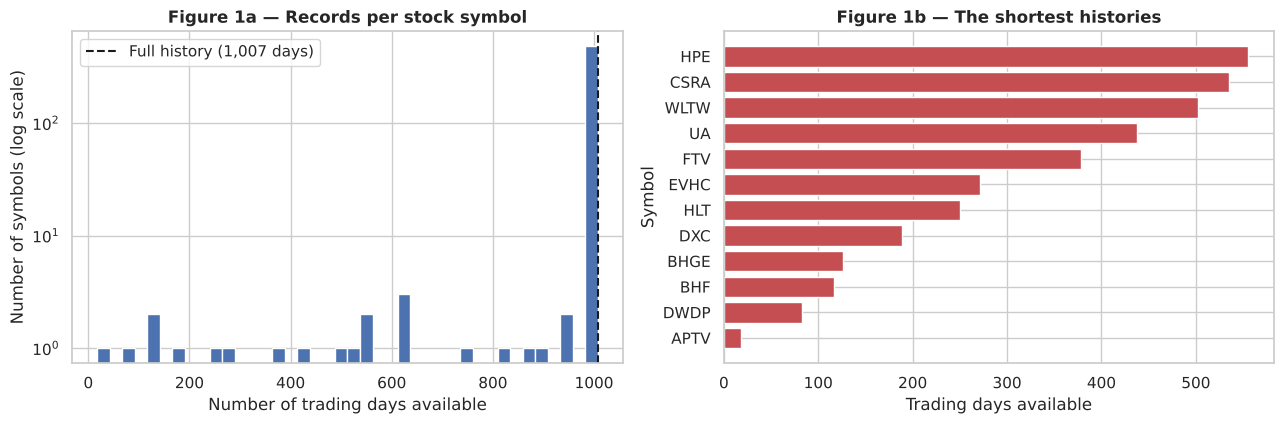

479 symbols have the full 1,007 days; 26 do not (they joined, left or were renamed during 2014 – 2017).


In [4]:
miss = df[df[PRICE_COLS].isna().any(axis=1)][["symbol", "date", "open", "high", "low", "close", "volume"]]
print(f"{len(miss)} rows with a missing open, high or low:"); display(miss)
counts = df.groupby("symbol").size()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
ax[0].hist(counts, bins=40, color=PAL[0]); ax[0].set_yscale("log"); ax[0].axvline(1007, color="k", ls="--", label="Full history (1,007 days)")
ax[0].set_title("Figure 1a — Records per stock symbol", fontsize=12); ax[0].set_xlabel("Number of trading days available"); ax[0].set_ylabel("Number of symbols (log scale)"); ax[0].legend()
short = counts[counts < 1007].sort_values().head(12)
ax[1].barh(short.index, short.values, color=PAL[3]); ax[1].set_title("Figure 1b — The shortest histories", fontsize=12); ax[1].set_xlabel("Trading days available"); ax[1].set_ylabel("Symbol")
save_fig("01_incomplete_histories.png")
print(f"{(counts == 1007).sum()} symbols have the full 1,007 days; {(counts < 1007).sum()} do not (they joined, left or were renamed during 2014 – 2017).")

**Treatment decisions (documented):**
* **Missing open/high/low values** are **never replaced by zero**. For the stock we model, no value is missing (checked and asserted in code), so no imputation is needed. If a modelled stock had a gap, the sensible repair for a missing open would be the previous close (or the row would be dropped), and a missing high/low would be set from the open and close.
* **Zero-volume placeholder rows** are excluded for any stock that has them (the code asserts that the chosen stock has none).
* **Incomplete histories (26 symbols):** a stock is only analysed or modelled if its history is complete, so it cannot appear to "start" or "stop" part-way through.

### 2.4 Unusual price observations: are the prices adjusted for splits and spin-offs?
The assignment warns that no adjusted-close field is supplied. We look for the signature of unadjusted corporate actions: single-day moves that are too large to be ordinary trading.

In [5]:
d2 = df.assign(ret_pct=df.groupby("symbol").close.pct_change() * 100)
big = d2[d2.ret_pct.abs() > 40][["symbol", "date", "close", "ret_pct"]].sort_values("date")
big["date"] = big.date.dt.date; display(big.round(1).reset_index(drop=True))
lnt = df[(df.symbol == "LNT") & df.date.between("2016-05-17", "2016-05-23")][["date", "close"]].reset_index(drop=True); print("LNT around the glitch:"); display(lnt)
aapl = get_stock(df, "AAPL")
print("AAPL closing price, first day:", round(aapl.close.iloc[0], 2), "| around the June 2014 7-for-1 split:", aapl.loc["2014-06-05":"2014-06-10", "close"].round(2).tolist())

,symbol,date,close,ret_pct
0,VRTX,2014-06-24,93.5,40.4
1,DISCA,2014-08-07,41.0,-50.6
2,DISCK,2014-08-07,39.8,-51.0
3,BAX,2015-07-01,38.9,-44.4
4,NI,2015-07-02,17.0,-62.6
5,EBAY,2015-07-20,28.6,-56.9
6,AMD,2016-04-22,4.0,52.3
7,LNT,2016-05-19,17.9,-49.4
8,LNT,2016-05-20,35.9,101.0
9,NWL,2017-09-15,43.2,40.2


LNT around the glitch:


,date,close
0,2016-05-17,35.99
1,2016-05-18,35.35
2,2016-05-19,17.87
3,2016-05-20,35.91
4,2016-05-23,35.75


AAPL closing price, first day: 79.02 | around the June 2014 7-for-1 split: [92.48, 92.22, 93.7, 94.25]


**Findings.**
* **Ten single-day moves exceed 40%** (and 39 exceed 25%). Five are single-day drops of 44 – 63% (BAX, NI, EBAY, DISCA and DISCK), which look like splits, spin-offs or share distributions that were **not** adjusted, rather than ordinary market moves. Three look like news-driven jumps (AMD +52%, VRTX +40%, NWL +40%); the data cannot confirm the causes. One symbol (LNT) shows a −49% day followed by +101% the next day, which is a **one-day data glitch** (the price is halved for a single day and then restored).
* **The file is not consistently adjusted.** AAPL, on the other hand, shows **no break at its June 2014 7-for-1 split** and starts near 79 in January 2014, when the shares actually traded around 550. That indicates AAPL's prices are *split-adjusted*, while other symbols (DISCA/DISCK) are not. Whether dividends are adjusted cannot be verified.
* **Consequence:** raw prices of an arbitrary symbol cannot be trusted for long-horizon returns, so the stock must be chosen with these breaks in mind, and the limitation stays in the report. Currency: the file has no currency column and the companies are US-listed, so prices are **assumed to be US dollars**.

## 3. Choosing the stock
A stock is only suitable if its history is complete, has no missing or inconsistent values, and has no unexplained corporate-action breaks.

In [6]:
cands = []
for s in ["AAPL", "MSFT", "JPM", "XOM", "JNJ", "KO", "AMZN", "GOOGL"]:
    x = df[df.symbol == s].set_index("date"); r = x.close.pct_change().abs() * 100
    bad = ((x.high < x[["open", "close", "low"]].max(axis=1)) | (x.low > x[["open", "close", "high"]].min(axis=1))).sum()
    cands.append({"symbol": s, "days": len(x), "missing cells": int(x.isna().sum().sum()), "inconsistent rows": int(bad), "largest daily move %": round(r.max(), 1),
                  "min close": round(x.close.min(), 1), "max close": round(x.close.max(), 1), "avg daily volume (m)": round(x.volume.mean() / 1e6, 1)})
pd.DataFrame(cands).set_index("symbol")

,days,missing cells,inconsistent rows,largest daily move %,min close,max close,avg daily volume (m)
symbol,,,,,,,
AAPL,1007,0,0,8.2,71.4,176.4,45.2
MSFT,1007,0,0,10.5,35.0,86.8,30.7
JPM,1007,0,0,8.3,53.1,107.8,15.7
XOM,1007,0,0,5.5,68.7,104.4,12.3
JNJ,1007,0,0,5.0,86.6,143.6,7.3
KO,1007,0,0,6.0,37.1,47.4,13.6
AMZN,1007,0,0,14.1,287.0,1195.8,3.9
GOOGL,1007,0,0,16.3,497.1,1085.1,2.1


**Decision: AAPL.** It has the full 1,007 days, **no missing values, no inconsistent rows, no corporate-action break** (largest move 8.2%), very high liquidity, and prices that rise sharply in 2017, which creates exactly the situation that tests whether a price model can handle new price levels. The pipeline takes the symbol as a parameter, and Section 9 repeats the main test on five more stocks.

## 4. Exploring AAPL

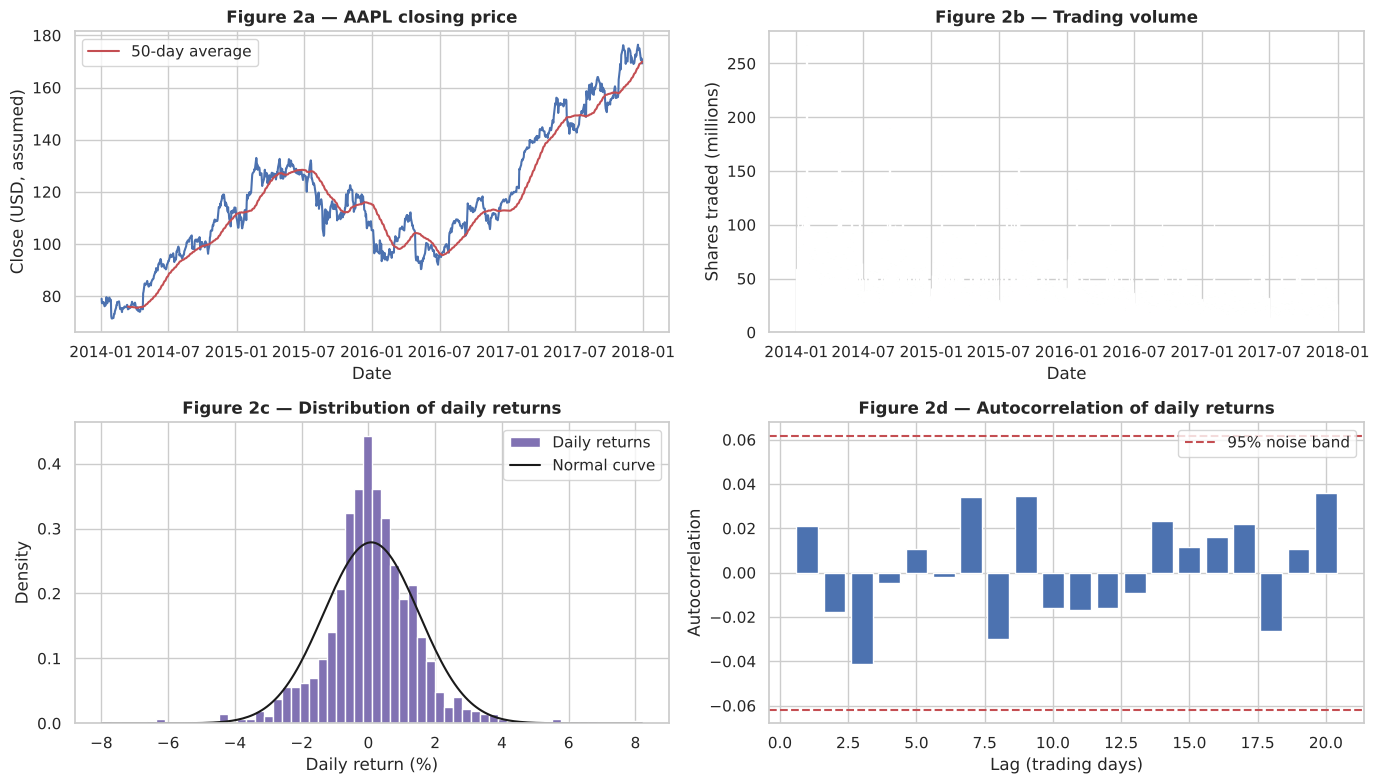

Daily return: mean 0.086% | std 1.43% | skew 0.02 | excess kurtosis 4.63 | share of up days 52.1%
Autocorrelation of returns at lags 1-5: [0.021, -0.018, -0.041, -0.005, 0.01] | noise band +/-0.062


In [7]:
a = get_stock(df, "AAPL"); ret = a.close.pct_change().dropna() * 100
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
ax[0, 0].plot(a.index, a.close, color=PAL[0]); ax[0, 0].plot(a.index, a.close.rolling(50).mean(), color=PAL[3], label="50-day average")
ax[0, 0].set_title("Figure 2a — AAPL closing price", fontsize=12); ax[0, 0].set_xlabel("Date"); ax[0, 0].set_ylabel("Close (USD, assumed)"); ax[0, 0].legend()
ax[0, 1].bar(a.index, a.volume / 1e6, color=PAL[2], width=1.5); ax[0, 1].set_title("Figure 2b — Trading volume", fontsize=12); ax[0, 1].set_xlabel("Date"); ax[0, 1].set_ylabel("Shares traded (millions)")
ax[1, 0].hist(ret, bins=60, color=PAL[4], density=True, label="Daily returns"); xs = np.linspace(ret.min(), ret.max(), 200)
ax[1, 0].plot(xs, stats.norm.pdf(xs, ret.mean(), ret.std()), color="k", label="Normal curve"); ax[1, 0].set_title("Figure 2c — Distribution of daily returns", fontsize=12)
ax[1, 0].set_xlabel("Daily return (%)"); ax[1, 0].set_ylabel("Density"); ax[1, 0].legend()
ac = acf(ret.values, nlags=20)[1:]; ax[1, 1].bar(range(1, 21), ac, color=PAL[0]); ci = 1.96 / np.sqrt(len(ret))
ax[1, 1].axhline(ci, color="r", ls="--", label="95% noise band"); ax[1, 1].axhline(-ci, color="r", ls="--")
ax[1, 1].set_title("Figure 2d — Autocorrelation of daily returns", fontsize=12); ax[1, 1].set_xlabel("Lag (trading days)"); ax[1, 1].set_ylabel("Autocorrelation"); ax[1, 1].legend()
save_fig("02_aapl_exploration.png")
print(f"Daily return: mean {ret.mean():.3f}% | std {ret.std():.2f}% | skew {ret.skew():.2f} | excess kurtosis {ret.kurt():.2f} | share of up days {(ret > 0).mean() * 100:.1f}%")
print(f"Autocorrelation of returns at lags 1-5: {[round(float(x), 3) for x in ac[:5]]} | noise band +/-{ci:.3f}")

**What this means for prediction.**
* The price rose strongly (about 71 → 176), so levels in 2017 are far above anything seen in 2014 – 2016.
* **Daily returns have almost no autocorrelation** (lag-1 = 0.02, inside the noise band at every lag). Yesterday's return tells us essentially nothing about today's. That is the single most important fact for this task: it means the best forecast of tomorrow's price is very close to **today's price**.
* Returns have **fat tails** (excess kurtosis 4.6): occasional large days happen more often than a normal curve suggests, so a few big misses are unavoidable.

## 5. Feature engineering (Task 3)
Row *t* describes trading day *t*, and **every feature uses only information up to the close of day t-1**.

| Feature | Definition | Why |
|---|---|---|
| `prev_close`, `prev_open`, `prev_high`, `prev_low`, `prev_volume` | Values of the previous trading day | Required; the latest known price level and activity |
| `ma_5`, `ma_10`, `ma_20` | Mean of the 5, 10, 20 closes ending at t-1 | Required; short-, medium- and longer-term trend |
| `prev_return_pct` | % change from t-2 to t-1 | Required; most recent momentum |
| *Extras for the return-target model (scale-free):* | | |
| `prev_open_gap_pct`, `prev_range_pct` | Open vs close, and (high − low) ÷ close of t-1 | Intraday behaviour independent of the price level |
| `close_vs_ma5/10/20_pct` | Close of t-1 relative to its moving averages | Is the stock stretched above/below its trend? |
| `volume_vs_avg20` | Volume of t-1 ÷ its 20-day average | Unusual activity |
| `ret_2d_pct`, `ret_5d_pct`, `vol_10d_pct` | Short-horizon returns and recent volatility | Momentum and risk regime |

Moving averages and rolling statistics are computed on a series **already shifted by one day**, so day *t* never enters its own features. Three automated tests prove this:

In [8]:
s = a.astype(float); DROP = ["close", "target_return_pct"]
k = 500; alt = s.copy(); alt.iloc[k:] = alt.iloc[k:] * 1.7
print("Test 1 - changing every price from day k onward leaves earlier features unchanged:",
      np.allclose(build_features(s).iloc[:k].drop(columns=DROP).dropna().values, build_features(alt).iloc[:k].drop(columns=DROP).dropna().values))
h = 400; alt2 = s.copy(); alt2.iloc[h] = alt2.iloc[h] * 3
print("Test 2 - day t's own prices and volume do not enter its features:",
      np.allclose(build_features(s).iloc[h].drop(DROP).values.astype(float), build_features(alt2).iloc[h].drop(DROP).values.astype(float)))
i = 300; fp = features_for_prediction(s.iloc[i - HISTORY_DAYS:i])
print("Test 3 - the API's single-row features equal the training features:", np.allclose(fp.values.astype(float), build_features(s).iloc[[i]].drop(columns=DROP).values.astype(float)))
table = training_table(a)
print(f"\nTraining table: {len(table)} rows ({HISTORY_DAYS} warm-up days removed) | 'previous day' check: prev_close[10] == close[9] -> {np.isclose(build_features(s)['prev_close'].iloc[10], s['close'].iloc[9])}")
table[REQUIRED_FEATURES + ["close"]].head(3).round(2)

Test 1 - changing every price from day k onward leaves earlier features unchanged: True
Test 2 - day t's own prices and volume do not enter its features: True
Test 3 - the API's single-row features equal the training features: True

Training table: 987 rows (20 warm-up days removed) | 'previous day' check: prev_close[10] == close[9] -> True


,prev_close,prev_open,prev_high,prev_low,prev_volume,ma_5,ma_10,ma_20,prev_return_pct,close
date,,,,,,,,,,
2014-01-31,71.40,71.79,72.36,70.96,169762789.0,74.39,76.50,77.04,-0.19,71.51
2014-02-03,71.51,70.74,71.65,70.51,116336444.0,73.09,75.74,76.67,0.16,71.65
2014-02-04,71.65,71.80,72.53,71.33,100620772.0,71.69,75.18,76.38,0.19,72.68


## 6. Chronological split and a warning sign
Data are split **in time order and never shuffled**:

| Set | Period | Trading days | Use |
|---|---|---|---|
| Train | 31 Jan 2014 – 30 Jun 2016 | 609 | Fit models |
| Validation | 1 Jul – 30 Dec 2016 | 127 | Choose models and settings; early stopping |
| **Test** | 3 Jan – 29 Dec 2017 | 251 | **Used once** for the final report |

After selection, the model is refitted on train + validation and scored once on the test year.

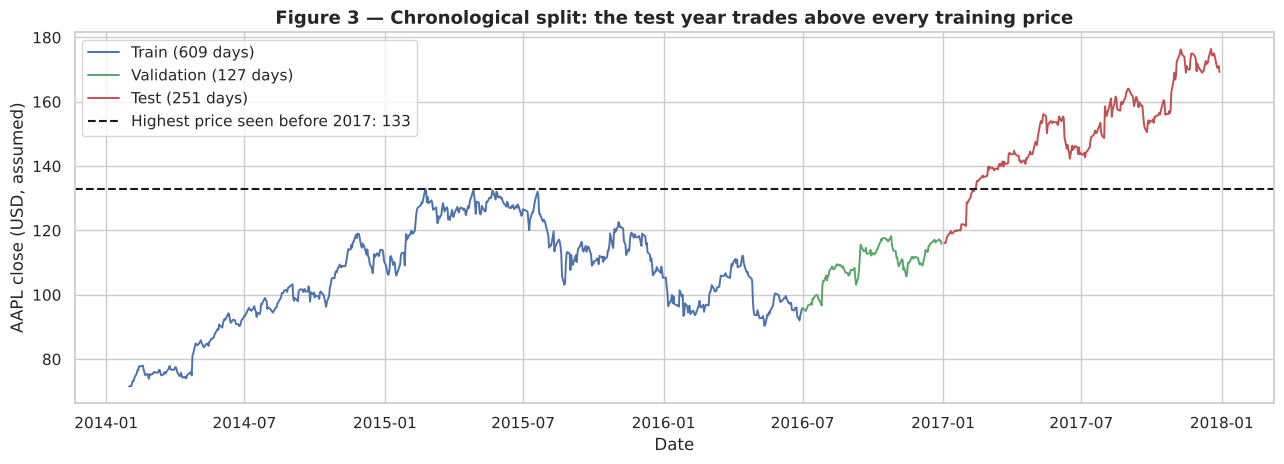

88.8% of test days close ABOVE the highest price in the training and validation data


In [9]:
tr, va, te = split(table)
fig, ax = plt.subplots(figsize=(13, 4.8))
for part, col, lab in [(tr, PAL[0], "Train"), (va, PAL[2], "Validation"), (te, PAL[3], "Test")]:
    ax.plot(part.index, part.close, color=col, lw=1.4, label=f"{lab} ({len(part)} days)")
mx = pd.concat([tr, va]).close.max(); ax.axhline(mx, color="k", ls="--", label=f"Highest price seen before 2017: {mx:.0f}")
ax.set_title("Figure 3 — Chronological split: the test year trades above every training price"); ax.set_xlabel("Date"); ax.set_ylabel("AAPL close (USD, assumed)"); ax.legend()
save_fig("03_split.png")
share = (te.close > mx).mean(); print(f"{share * 100:.1f}% of test days close ABOVE the highest price in the training and validation data")

**This matters a great deal.** On **89% of test days** AAPL closes above the highest price the model ever saw in training and validation. Tree-based models such as XGBoost can only output values built from the training targets, so a model that predicts the **price level directly** cannot predict a price it has never seen. Section 8 shows what that does. (The model that predicts the **return** and converts it to a price does not have this problem.)

## 7. Baselines and MLflow experiments (Tasks 4, 5 and 7)
`python src/train.py` runs every experiment below (about 20 seconds) and logs each one to MLflow (`mlflow.db`, artifacts in `mlartifacts/`). Set `RUN_TRAINING = True` to run them from this notebook (this adds new runs).

| Stage | Runs | Idea |
|---|---|---|
| **Baselines** | repeat last close; 5-day average; 20-day average; last close + average training drift | The bar a model must clear |
| **Ridge regression** | price target; return target | A simple model that can extrapolate |
| **XGBoost, direct price** (as assigned) | 3 settings | Target = next close, the nine required features |
| **XGBoost, return target** | 20 seeded random settings | Target = next-day % return; price = last close × (1 + predicted return); scale-free features |
| **Finals** | selected XGBoost and the best direct XGBoost, refitted on train + validation, scored once on test | Report |

**Selection rule:** the XGBoost run with the lowest **validation RMSE (in price)**. The test year plays no part in choosing.

In [10]:
RUN_TRAINING = False
if RUN_TRAINING:
    from src.train import run_experiments
    run_experiments("AAPL")
mlflow.set_tracking_uri(f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}")
runs = mlflow.search_runs(experiment_names=["aapl-next-day-close"], order_by=["start_time ASC"])
view = runs[["tags.mlflow.runName", "tags.run_kind", "metrics.val_MAE", "metrics.val_RMSE", "metrics.val_R2", "metrics.test_MAE", "metrics.test_RMSE", "metrics.test_R2"]].copy()
view.columns = ["run", "kind", "val_MAE", "val_RMSE", "val_R2", "test_MAE", "test_RMSE", "test_R2"]
print(f"{len(view)} tracked runs"); view.round(3)

31 tracked runs


,run,kind,val_MAE,val_RMSE,val_R2,test_MAE,test_RMSE,test_R2
0,baseline_naive_last_close,baseline,0.889,1.294,0.953,1.186,1.752,0.986
1,baseline_moving_average_5,baseline,1.557,2.086,0.879,1.931,2.562,0.969
2,baseline_moving_average_20,baseline,3.138,3.746,0.610,3.993,5.014,0.882
3,baseline_last_close_plus_train_drift,baseline,0.886,1.288,0.954,1.183,1.745,0.986
4,ridge_direct_price,linear-model,0.932,1.290,0.954,NaN,NaN,NaN
5,ridge_return_target,linear-model,0.874,1.274,0.955,NaN,NaN,NaN
6,xgb_direct_price_0,xgboost-direct,1.106,1.484,0.939,NaN,NaN,NaN
7,xgb_direct_price_1,xgboost-direct,1.103,1.486,0.939,NaN,NaN,NaN
8,xgb_direct_price_2,xgboost-direct,1.161,1.536,0.934,NaN,NaN,NaN
9,xgb_return_00,xgboost-return,0.884,1.287,0.954,NaN,NaN,NaN


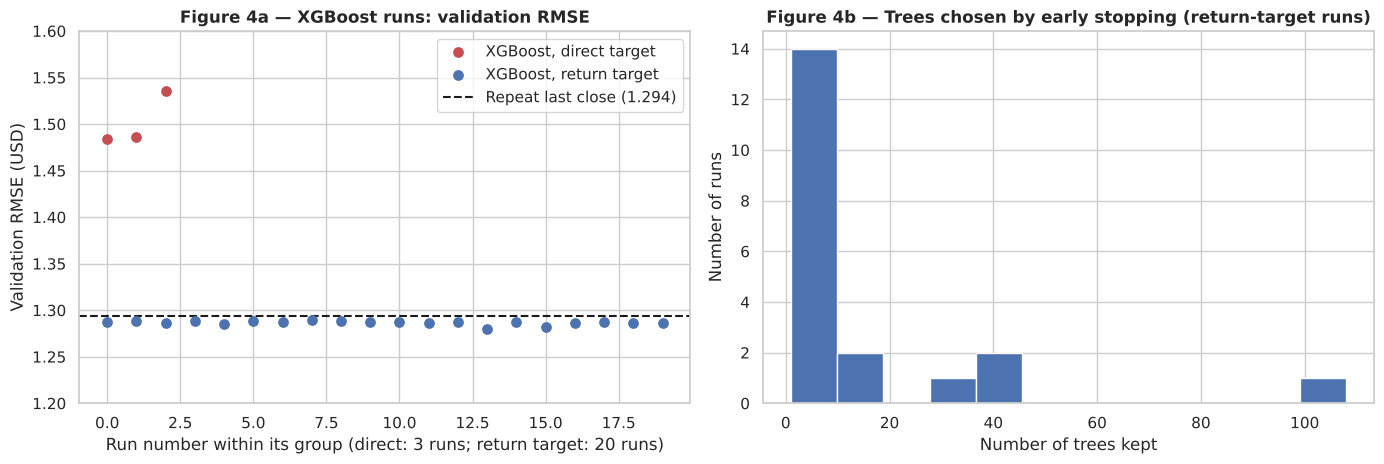

Selected: xgb_return_13 | validation RMSE 1.2802 vs naive 1.2938 | trees: 18
Selected parameters: {'max_depth': 4, 'learning_rate': 0.05, 'min_child_weight': 10, 'subsample': 0.9, 'colsample_bytree': 0.5, 'reg_lambda': 1.0, 'gamma': 0.5}
Range of validation RMSE: direct 1.484 - 1.536 | return 1.28 - 1.29


In [11]:
res = json.load(open(ROOT / "reports/experiment_results.json")); selr = res["selection"]
cand = pd.DataFrame([{"run": c["run"], "kind": c["kind"], "val_RMSE": c["val"]["RMSE"], "val_MAE": c["val"]["MAE"], "trees": c["best_iteration"] + 1} for c in res["candidates"]])
naive_v = selr["naive_val"]["RMSE"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for kind, col in [("direct", PAL[3]), ("return", PAL[0])]:
    sub = cand[cand.kind == kind]; ax[0].scatter(range(len(sub)), sub.val_RMSE, color=col, s=45, label=f"XGBoost, {kind} target", zorder=3)
ax[0].axhline(naive_v, color="k", ls="--", label=f"Repeat last close ({naive_v:.3f})"); ax[0].set_ylim(1.2, 1.6)
ax[0].set_title("Figure 4a — XGBoost runs: validation RMSE", fontsize=12); ax[0].set_xlabel("Run number within its group (direct: 3 runs; return target: 20 runs)"); ax[0].set_ylabel("Validation RMSE (USD)"); ax[0].legend()
ax[1].hist(cand[cand.kind == "return"].trees, bins=12, color=PAL[0]); ax[1].set_title("Figure 4b — Trees chosen by early stopping (return-target runs)", fontsize=12)
ax[1].set_xlabel("Number of trees kept"); ax[1].set_ylabel("Number of runs")
save_fig("04_experiments.png")
print("Selected:", selr["best_run"], "| validation RMSE", round(selr["val"]["RMSE"], 4), "vs naive", round(naive_v, 4), "| trees:", selr["best_iteration"] + 1)
print("Selected parameters:", selr["params"])
print("Range of validation RMSE: direct", round(cand[cand.kind == 'direct'].val_RMSE.min(), 3), "-", round(cand[cand.kind == 'direct'].val_RMSE.max(), 3),
      "| return", round(cand[cand.kind == 'return'].val_RMSE.min(), 3), "-", round(cand[cand.kind == 'return'].val_RMSE.max(), 3))

**How the model was chosen.**
* The direct-price XGBoost runs (validation RMSE about 1.48 – 1.54) are **worse than the naive baseline (1.294)**.
* All 20 return-target runs land in a very narrow band (**1.280 – 1.290**), almost identical to the baseline, and early stopping keeps very few trees (often 1 – 20): the algorithm keeps finding that more trees only fit noise. The best, `xgb_return_13`, is better than the baseline by only about 1%, which is well within what luck can produce when picking the best of 20.
* **Selected: `xgb_return_13`** (validation RMSE 1.280, 18 trees). A ridge regression on the same features scores 1.274, marginally better still, which confirms that the differences are noise.

## 8. Results on the untouched test year (Tasks 5 and 6)

,model,MAE,RMSE,R2,MAPE_pct,R2_of_returns,direction_accuracy_pct
0,Baseline: repeat last close,1.186,1.752,0.986,0.776,-0.019,NaN
1,Baseline: 5-day moving average,1.930,2.562,0.969,1.267,-1.140,47.410
2,Baseline: 20-day moving average,3.993,5.014,0.882,2.662,-7.431,44.622
3,Baseline: last close + training drift,1.183,1.745,0.986,0.774,-0.007,54.582
4,XGBoost direct price,22.279,25.775,-2.116,14.088,-190.928,46.215
5,XGBoost return target - selected,1.178,1.754,0.986,0.770,-0.016,53.785


Selected XGBoost vs repeat-last-close: MAE 1.178 vs 1.186 (-0.6%), RMSE 1.754 vs 1.752 (+0.1%), R2 0.9856 vs 0.9856
Direct-price XGBoost (as assigned):    MAE 22.28 (USD), RMSE 25.77, R2 -2.12


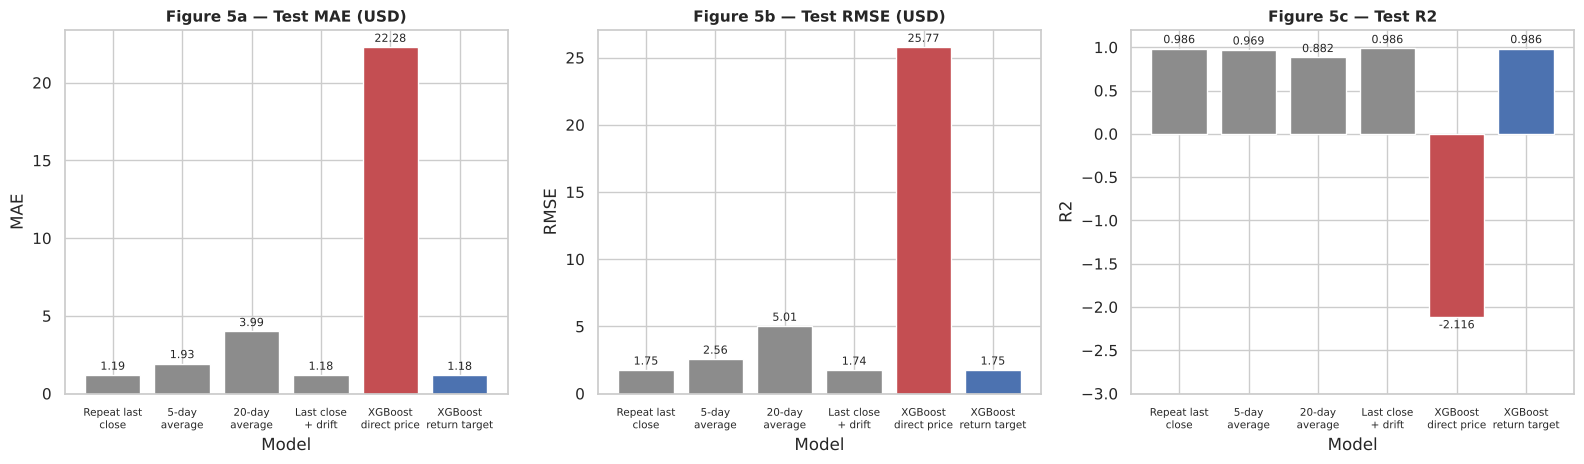

In [12]:
summary = pd.read_csv(ROOT / "reports/test_metrics_summary.csv")
summary["model"] = summary.model.str.replace(r" \(xgb_.*?\)", "", regex=True)
display(summary.round(3))
nv, sl, dr = [summary.iloc[i] for i in (0, 5, 4)]
print(f"Selected XGBoost vs repeat-last-close: MAE {sl.MAE:.3f} vs {nv.MAE:.3f} ({(sl.MAE / nv.MAE - 1) * 100:+.1f}%), RMSE {sl.RMSE:.3f} vs {nv.RMSE:.3f} ({(sl.RMSE / nv.RMSE - 1) * 100:+.1f}%), R2 {sl.R2:.4f} vs {nv.R2:.4f}")
print(f"Direct-price XGBoost (as assigned):    MAE {dr.MAE:.2f} (USD), RMSE {dr.RMSE:.2f}, R2 {dr.R2:.2f}")
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
short = ["Repeat last\nclose", "5-day\naverage", "20-day\naverage", "Last close\n+ drift", "XGBoost\ndirect price", "XGBoost\nreturn target"]
for a_, metric in zip(ax, ["MAE", "RMSE", "R2"]):
    vals = summary[metric].values; cols = [PAL[7]] * 4 + [PAL[3], PAL[0]]
    bars = a_.bar(short, vals, color=cols); a_.bar_label(bars, fmt="%.2f" if metric != "R2" else "%.3f", padding=2, fontsize=8)
    a_.set_title(f"Figure 5{'abc'[['MAE','RMSE','R2'].index(metric)]} — Test {metric}{' (USD)' if metric != 'R2' else ''}", fontsize=11); a_.set_xlabel("Model"); a_.set_ylabel(metric)
    plt.setp(a_.get_xticklabels(), fontsize=7.5)
    if metric == "R2": a_.set_ylim(-3, 1.2)
save_fig("05_test_metrics.png")

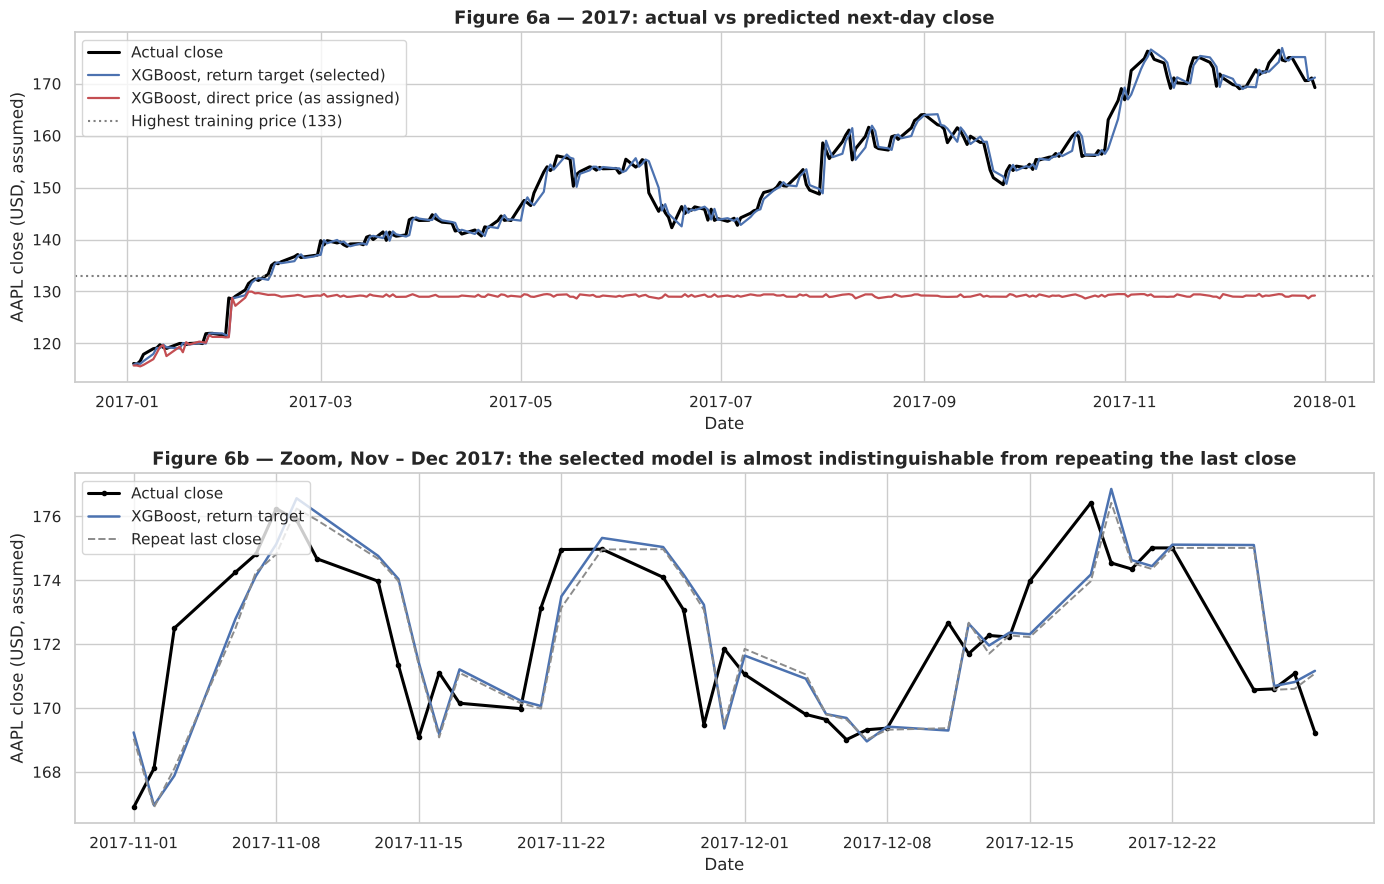

In [13]:
p = pd.read_csv(ROOT / "data/processed/test_predictions.csv", parse_dates=["date"]).set_index("date")
fig, ax = plt.subplots(2, 1, figsize=(14, 9))
ax[0].plot(p.index, p.actual_close, color="black", lw=2.2, label="Actual close"); ax[0].plot(p.index, p.xgb_selected, color=PAL[0], lw=1.6, label="XGBoost, return target (selected)")
ax[0].plot(p.index, p.xgb_direct, color=PAL[3], lw=1.6, label="XGBoost, direct price (as assigned)"); ax[0].axhline(133.0, color="grey", ls=":", label="Highest training price (133)")
ax[0].set_title("Figure 6a — 2017: actual vs predicted next-day close"); ax[0].set_xlabel("Date"); ax[0].set_ylabel("AAPL close (USD, assumed)"); ax[0].legend(loc="upper left")
z = p.loc["2017-11-01":"2017-12-29"]
ax[1].plot(z.index, z.actual_close, color="black", lw=2.2, marker="o", ms=3, label="Actual close"); ax[1].plot(z.index, z.xgb_selected, color=PAL[0], lw=1.8, label="XGBoost, return target")
ax[1].plot(z.index, z.prev_close, color=PAL[7], lw=1.4, ls="--", label="Repeat last close")
ax[1].set_title("Figure 6b — Zoom, Nov – Dec 2017: the selected model is almost indistinguishable from repeating the last close"); ax[1].set_xlabel("Date"); ax[1].set_ylabel("AAPL close (USD, assumed)"); ax[1].legend(loc="upper left")
save_fig("06_actual_vs_predicted.png")

**Reading the results**
* **R² = 0.986 is not an achievement.** Simply repeating yesterday's close also scores **0.9856**. Prices trend, so any price-based method that stays close to the previous price gets an R² near 1. R² on price levels cannot tell a good model from none, which is why the model is compared with the baseline and also scored on *returns*.
* **The selected XGBoost does not improve on the baseline.** MAE 1.178 vs 1.186 USD (−0.7%), RMSE 1.754 vs 1.752 (+0.1%): the same, to within rounding. An average error of about **$1.18, or 0.77% of the price**, is simply the size of an ordinary day's move.
* **The XGBoost that predicts price directly fails badly:** MAE **22.3 USD**, R² **−2.12**, far worse than a flat line. Figure 6a shows why: its predictions stop at about 133 (the training maximum) while the actual price climbs to 176.

### 8.1 Why can't the model do better? Evidence

In [14]:
te_ = te.copy(); te_["sel"] = p.xgb_selected.values
err_m, err_n = np.abs(te_.close - te_.sel), np.abs(te_.close - te_.prev_close)
w = stats.wilcoxon(err_n - err_m)
act_up = (te_.close > te_.prev_close); pred_up = (te_.sel > te_.prev_close)
dir_acc = (act_up == pred_up).mean(); n = len(te_)
base_rate = act_up.mean(); bt50 = stats.binomtest(int((act_up == pred_up).sum()), n, 0.5); btbase = stats.binomtest(int((act_up == pred_up).sum()), n, max(base_rate, 1 - base_rate))
ev = pd.DataFrame({"Evidence": ["R-squared of predicted vs actual daily RETURNS (0 = no skill)", "Share of days the model is closer to the true close than 'repeat last close'",
                                "Paired Wilcoxon test of absolute errors vs baseline (p-value; < 0.05 would mean a real difference)",
                                "Direction accuracy of the model (up vs down)", "Share of days AAPL actually closed up in 2017 (the 'always say up' strategy)",
                                "Binomial test: is direction accuracy better than a coin flip? (p-value)", "Binomial test: better than always guessing the more common direction? (p-value)"],
                   "Result": [f"{evaluate(te_.close, te_.sel, te_.prev_close)['R2_of_returns']:.3f}", f"{(err_m < err_n).mean() * 100:.1f}%", f"{w.pvalue:.3f}", f"{dir_acc * 100:.1f}%",
                              f"{base_rate * 100:.1f}%", f"{bt50.pvalue:.2f}", f"{btbase.pvalue:.2f}"]})
display(ev)

,Evidence,Result
0,R-squared of predicted vs actual daily RETURNS...,-0.016
1,Share of days the model is closer to the true ...,52.6%
2,Paired Wilcoxon test of absolute errors vs bas...,0.167
3,Direction accuracy of the model (up vs down),53.8%
4,Share of days AAPL actually closed up in 2017 ...,54.6%
5,Binomial test: is direction accuracy better th...,0.26
6,Binomial test: better than always guessing the...,0.80


**No evidence of skill.** The model explains none of the variation in daily returns (R² ≈ −0.02), is closer than the baseline on only 53% of days (about a coin flip), and the error difference is not statistically significant (p = 0.17). Its up/down accuracy of 53.8% is **not better than a coin flip (p = 0.26)** and is below the 54.6% you would get by always guessing "up" in a year when the stock mostly rose. This is consistent with the near-zero autocorrelation found in Section 4: **daily changes in this stock's price are essentially unpredictable from its own past prices and volume.**

### 8.2 Overfitting or underfitting?
The selected recipe and the direct-price recipe are refitted on the training period only, then scored on training, validation and test.

In [15]:
sel_c = [c for c in res["candidates"] if c["run"] == selr["best_run"]][0]; dir_c = [c for c in res["candidates"] if c["run"] == selr["best_direct_run"]][0]
def refit(kind, feats, target, params, n_trees):
    return fit_xgb(params, feats, target, tr, None, n_estimators=n_trees)
m_sel = refit("return", RATIO_FEATURES, "target_return_pct", selr["params"], selr["best_iteration"] + 1)
m_dir = refit("direct", REQUIRED_FEATURES, "close", DIRECT_CONFIGS[0], dir_c["best_iteration"] + 1)
rows = []
for label, m, feats, kind in [("XGBoost, return target (selected)", m_sel, RATIO_FEATURES, "return"), ("XGBoost, direct price", m_dir, REQUIRED_FEATURES, "direct")]:
    for part_name, part in [("train", tr), ("validation", va), ("test", te)]:
        pr = to_price(kind, m.predict(part[feats]), part.prev_close); e = evaluate(part.close, pr, part.prev_close)
        rows.append({"model": label, "period": part_name, "MAE (USD)": e["MAE"], "R2 (price)": e["R2"], "R2 of returns": e["R2_of_returns"]})
fit_tbl = pd.DataFrame(rows).round(3); display(fit_tbl)
nm = {"train": evaluate(tr.close, tr.prev_close)["MAE"], "validation": evaluate(va.close, va.prev_close)["MAE"], "test": evaluate(te.close, te.prev_close)["MAE"]}
print("Repeat-last-close MAE for reference:", {k: round(v, 3) for k, v in nm.items()})

,model,period,MAE (USD),R2 (price),R2 of returns
0,"XGBoost, return target (selected)",train,1.138,0.990,0.098
1,"XGBoost, return target (selected)",validation,0.878,0.954,0.005
2,"XGBoost, return target (selected)",test,1.187,0.985,-0.023
3,"XGBoost, direct price",train,1.066,0.992,0.264
4,"XGBoost, direct price",validation,1.106,0.939,-0.297
5,"XGBoost, direct price",test,22.600,-2.184,-195.372


Repeat-last-close MAE for reference: {'train': 1.191, 'validation': 0.889, 'test': 1.186}


* **Direct-price XGBoost: overfits and cannot extrapolate.** In training it does slightly better than repeating the last close (MAE 1.07 vs 1.19 USD) and its R² on returns is +0.26, but on validation it is already worse than the baseline (1.11 vs 0.89 USD, R² on returns −0.30), and on the test year its error explodes to **22.6 USD**. It has fitted the price levels and noise of 2014 – 2016 and cannot predict a price above those it has seen, a classic failure of tree models on trending data.
* **Return-target XGBoost: mild overfitting of noise, kept small by early stopping.** It learns a little in training (R² on returns 0.10, MAE 1.14 vs 1.19 for the baseline) that does not carry over: R² on returns is 0.005 on validation and −0.023 on test, and the test MAE equals the baseline's. The tiny size of the model (18 trees) is what stops the damage. There is **no real improvement to be found**: the features hold almost no predictive signal about tomorrow's return.

### 8.3 Walk-forward check through 2017
A single test year can be lucky. As a stability check, the selected recipe is refitted each month of 2017 using only earlier data, then used for that month and compared with the baselines.

,days,XGBoost,Repeat last close,Last close + drift
month,,,,
Jan,20,0.441,0.454,0.448
Feb,19,0.861,0.956,0.900
Mar,23,0.793,0.801,0.802
Apr,19,0.719,0.652,0.688
May,22,1.290,1.267,1.263
Jun,22,1.622,1.608,1.622
Jul,20,0.915,0.972,0.931
Aug,23,1.847,1.869,1.824
Sep,20,1.503,1.404,1.476


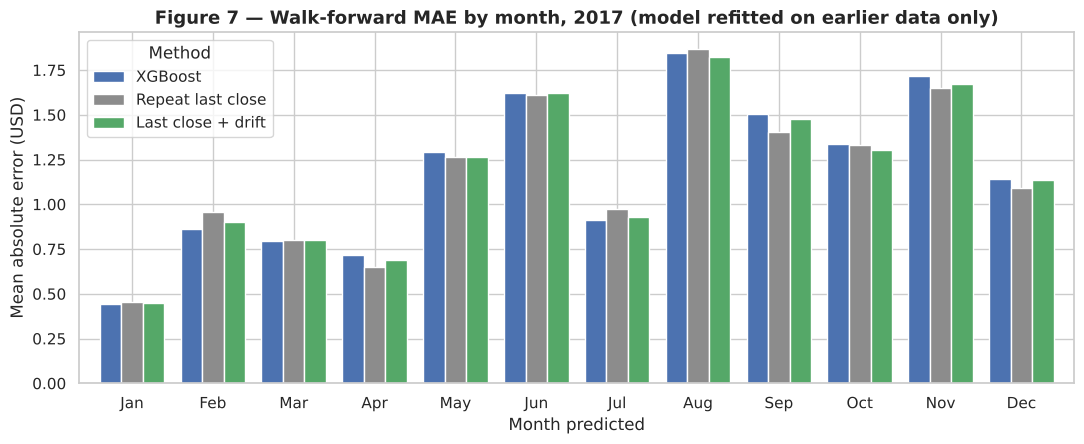

XGBoost beats 'repeat last close' in 5 of 12 months;  overall MAE: XGBoost 1.197 vs baseline 1.186


In [16]:
params = {**selr["params"]}; n_trees = selr["best_iteration"] + 1
tr_full = pd.concat([tr, va]); rows = []
for m in range(1, 13):
    start = pd.Timestamp(f"2017-{m:02d}-01"); end = start + pd.offsets.MonthEnd(0)
    past, month = table.loc[: start - pd.Timedelta(days=1)], table.loc[start:end]
    mdl = fit_xgb(params, RATIO_FEATURES, "target_return_pct", past, None, n_estimators=n_trees)
    drift = past.target_return_pct.mean()
    rows.append({"month": start.strftime("%b"), "days": len(month),
                 "XGBoost": evaluate(month.close, to_price("return", mdl.predict(month[RATIO_FEATURES]), month.prev_close))["MAE"],
                 "Repeat last close": evaluate(month.close, month.prev_close)["MAE"],
                 "Last close + drift": evaluate(month.close, month.prev_close * (1 + drift / 100))["MAE"]})
wf = pd.DataFrame(rows).set_index("month").round(3); display(wf)
fig, ax = plt.subplots(figsize=(11, 4.6)); wf.drop(columns="days").plot(kind="bar", ax=ax, width=0.8, color=[PAL[0], PAL[7], PAL[2]])
ax.set_title("Figure 7 — Walk-forward MAE by month, 2017 (model refitted on earlier data only)"); ax.set_xlabel("Month predicted"); ax.set_ylabel("Mean absolute error (USD)"); plt.xticks(rotation=0); ax.legend(title="Method")
save_fig("07_walk_forward.png")
print("XGBoost beats 'repeat last close' in", int((wf.XGBoost < wf['Repeat last close']).sum()), "of 12 months;  overall MAE: XGBoost", round(np.average(wf.XGBoost, weights=wf.days), 3), "vs baseline", round(np.average(wf['Repeat last close'], weights=wf.days), 3))

**No consistent edge.** XGBoost beats "repeat last close" in only **5 of 12 months**, loses in the other 7, and over the whole year its MAE (1.197) is slightly **worse** than the baseline's (1.186). The monthly differences are tiny and change sign, which is what pure noise looks like. This confirms that the single test-year result (a tie) is not hiding a real advantage.

## 9. Does the finding hold for other stocks?
The same recipe (return-target XGBoost with the selected settings, and the direct-price version) is applied to five other stocks with clean histories, using the same split.

In [17]:
rows = []
dir_trees = dir_c["best_iteration"] + 1
for sym in ["MSFT", "JPM", "XOM", "JNJ", "KO"]:
    tb = training_table(get_stock(df, sym)); trs, vas, tes = split(tb); trv = pd.concat([trs, vas])
    m_r = fit_xgb(selr["params"], RATIO_FEATURES, "target_return_pct", trv, None, n_estimators=int((selr["best_iteration"] + 1) * 1.1))
    m_d = fit_xgb(DIRECT_CONFIGS[0], REQUIRED_FEATURES, "close", trv, None, n_estimators=int(dir_trees * 1.1))
    pr = evaluate(tes.close, to_price("return", m_r.predict(tes[RATIO_FEATURES]), tes.prev_close), tes.prev_close)
    pdn = evaluate(tes.close, to_price("direct", m_d.predict(tes[REQUIRED_FEATURES]), tes.prev_close))
    nvv = evaluate(tes.close, tes.prev_close, tes.prev_close)
    rows.append({"stock": sym, "test days above train max %": round((tes.close > trv.close.max()).mean() * 100, 0), "repeat-last-close MAE": nvv["MAE"], "XGBoost return MAE": pr["MAE"],
                 "XGBoost direct MAE": pdn["MAE"], "return model vs baseline %": (pr["MAE"] / nvv["MAE"] - 1) * 100, "R2 of returns (return model)": pr["R2_of_returns"]})
others = pd.DataFrame(rows).set_index("stock").round(3); others

,test days above train max %,repeat-last-close MAE,XGBoost return MAE,XGBoost direct MAE,return model vs baseline %,R2 of returns (return model)
stock,,,,,,
MSFT,92.0,0.468,0.464,9.337,-0.837,0.000
JPM,72.0,0.681,0.684,6.475,0.336,0.001
XOM,0.0,0.453,0.452,0.499,-0.193,-0.016
JNJ,70.0,0.665,0.671,7.302,0.893,-0.018
KO,0.0,0.194,0.195,0.237,0.394,-0.008


**The same story for every stock.** The return-target model is within about ±1% of "repeat last close" for all five (MAE change from −0.8% to +0.9%) with an R² on returns of essentially zero, so there is no consistent gain. The **direct-price** model, in contrast, fails exactly where the test prices rise above the training range: MSFT (92% of test days above the training maximum, MAE 9.34 vs 0.47 for the baseline), JPM (72%, 6.48 vs 0.68) and JNJ (70%, 7.30 vs 0.67). For XOM and KO, whose test prices stay inside the training range, the direct model is merely slightly worse than the baseline (0.50 vs 0.45 and 0.24 vs 0.19). The cause of the failure is therefore the price range, not anything specific to AAPL.

## 10. Deployment with FastAPI (Task 8)
`app/main.py` loads the selected model and exposes:

| Endpoint | Purpose |
|---|---|
| `GET /health` | Is the model loaded? |
| `GET /model-info` | Features, training window, metrics, whether it beat the baseline, disclaimer |
| `POST /predict` | Predicted next-trading-day close |

**Input:** the symbol and the **last 20 trading days** of open, high, low, close and volume (the API builds every feature itself with the *same code as training*). **Validation:** the symbol must be the one the model was trained on; exactly 20 records; positive prices and volumes; high/low consistent with open/close; strictly increasing dates; all fields present and correctly typed. Anything invalid returns **HTTP 422** with a clear message and **no prediction**. **Response:** the predicted close, the predicted % change, the baseline (last close), the model version, warnings (for example prices outside the training range or a model that did not beat the baseline) and a disclaimer.

In [18]:
from fastapi.testclient import TestClient
from app.main import app
from scripts.make_example_request import build
payload, actual, nxt = build("2017-12-27")
with TestClient(app) as client:
    r = client.post("/predict", json=payload); body = r.json()
    print("VALID request -> HTTP", r.status_code); print(json.dumps(body, indent=2))
    print(f"\nActual AAPL close on {nxt}: {actual:.2f} | model {body['predicted_next_close']:.2f} | repeat-last-close {body['baseline_next_close']:.2f}")
    bad = json.loads(json.dumps(payload)); bad["history"][5].update({"high": 100.0, "low": 150.0})
    r2 = client.post("/predict", json=bad); print("\nINVALID request (high price below low price) -> HTTP", r2.status_code); print(json.dumps(r2.json(), indent=2))

VALID request -> HTTP 200
{
  "symbol": "AAPL",
  "as_of_date": "2017-12-27",
  "predicted_next_close": 170.81,
  "predicted_change_pct": 0.125,
  "baseline_next_close": 170.6,
  "baseline_description": "repeat the last closing price",
  "currency": "USD (assumed; the dataset has no currency column)",
  "model_name": "xgb_aapl_next_close",
  "model_version": "1.0.0",
  "target_type": "return",
  "warnings": [
    "In testing, this model did not meaningfully improve on repeating the last close."
  ],
  "disclaimer": "Historical statistical model for education. Not investment advice; historical patterns do not guarantee future prices."
}

Actual AAPL close on 2017-12-28: 171.08 | model 170.81 | repeat-last-close 170.60

INVALID request (high price below low price) -> HTTP 422
{
  "error": "Invalid input - no prediction was made",
  "details": [
    {
      "field": "history.5",
      "problem": "inconsistent prices on 2017-12-06: high must be the highest and low the lowest of open/high/l

Twenty-nine automated tests (`pytest tests`) check that the audit reproduces the assignment's figures, three leakage rules, API/training feature equality, a valid prediction, sixteen kinds of invalid input, and the two warning rules; all pass. A transcript from a live `uvicorn` server is in `docs/api_evidence.txt`. The single example above is an illustration only: one day proves nothing about accuracy (Section 8 does).

## 11. Limitations, practical implications and recommendations
**Limitations**
* **Historical prices carry almost no information about tomorrow's return.** The evidence is consistent: near-zero autocorrelation, an R² on returns of about zero, a direction accuracy no better than chance, and no statistically significant gain over repeating the last close. Better features from the same data are unlikely to change this; real gains would need new information (news, fundamentals, order flow), and even then markets are hard to beat.
* **Corporate actions and adjustments are not verifiable.** The file has no adjusted close; some symbols show unadjusted splits or spin-offs and one has a one-day glitch. AAPL looks split-adjusted but dividend adjustment is unknown. The currency is assumed to be USD.
* **Price-level R² is misleading** and should never be reported alone for a trending series.
* **One stock, one test year (2017),** which was a strong, low-volatility year for equities. Results in a falling or turbulent market could differ.
* **Not a trading model.** No transaction costs, slippage or risk management are considered, and a tiny average error does not mean a profitable strategy.
* **The API is a prototype** with no authentication, monitoring or retraining, and it serves one stock.

**Practical implications.** A price model that cannot beat "tomorrow = today" should not drive decisions. The real value of this project is the *process*: leakage-proof features, chronological validation, honest baselines, tracked experiments and a validated API. The model is safe as a demonstration, and the API tells every caller that it did not improve on the baseline.

**Recommendations**
1. **Always report against the naive baseline** and on returns (not only price R²) for financial series.
2. **Predict something more forecastable.** Volatility clusters (squared returns show weak persistence) and is the more promising target for risk monitoring than the direction of price.
3. **For tree models, predict changes or ratios, not price levels,** or the model will fail as soon as prices leave the training range.
4. **Use adjusted prices and a verified corporate-action calendar** before any long-horizon work.
5. **Next steps:** try a volatility model (for example GARCH), add external data, evaluate over several market years and stocks, and add monitoring that compares live errors with the baseline.